# TP : MLP avec Keras sur le dataset Dry Bean

**Objectif :** reprendre la démarche du TP Digits sur un nouveau dataset : classer 7 types de haricots secs à partir de 16 mesures géométriques.

**Démarche :** comprendre les données → encoder et séparer sans fuite → construire → compiler → entraîner → évaluer → comparer des réglages → régulariser → arrêter au bon moment → sauvegarder.

**Différences avec Digits :**
- 16 variables (mesures) au lieu de 64 pixels
- 7 classes au lieu de 10
- cibles en texte, donc `LabelEncoder`
- classes déséquilibrées, donc F1 macro et rappel par classe

In [ ]:
!pip install ucimlrepo

## Étape 0 : Installation, imports et chargement

**Ce qu'on fait :** installer `ucimlrepo`, importer les bibliothèques, charger Dry Bean, fixer `SEED = 42`.

**Pourquoi :** `ucimlrepo` télécharge les données depuis UCI. Le seed rend les résultats reproductibles.

**À retenir :** X = 13611 lignes × 16 variables, y = type de haricot.

## Étape 1 : Lecture du MiniMLP NumPy (XNOR)

**Ce qu'on fait :** exécuter et lire le petit réseau 2-3-1, sans rien écrire.

**Les 4 étapes internes :**
1. `forward` : propagation avant
2. perte : mesure de l'erreur
3. rétropropagation : calcul des gradients (`D2`, `D1`, `dW1`, `dW2`)
4. mise à jour : `W -= rate * dW` (descente de gradient)

**Conclusion :** Keras fait tout cela automatiquement dans `fit`.

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from ucimlrepo import fetch_ucirepo

SEED = 42
keras.utils.set_random_seed(SEED)

dry_bean = fetch_ucirepo(id=602)
X = dry_bean.data.features
y = dry_bean.data.targets.values.ravel()
print(X.shape, y.shape)   # (13611, 16) (13611,)

(13611, 16) (13611,)


## Étape 2 : Comprendre les données

**Ce qu'on fait :** examiner les types, valeurs manquantes, doublons, effectifs par classe et échelles.

**Pourquoi :** on ne modélise pas à l'aveugle. Cela détermine le type de problème et les précautions à prendre.

**Observations :**
- 16 variables numériques, 7 classes : classification multi-classes
- échelles très différentes : la standardisation est indispensable
- classes déséquilibrées : l'accuracy seule peut tromper, il faut regarder le F1 macro et le rappel par classe

In [ ]:
print(X.dtypes)
print("Valeurs manquantes :", X.isna().sum().sum())
print(pd.Series(y).value_counts())
print("Doublons :", X.duplicated().sum())
print(X.describe().T[["min", "max", "mean"]])

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
dtype: object
Valeurs manquantes : 0
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
Doublons : 68
                          min            max          mean
Area             20420.000000  254616.000000  53048.284549
Perimeter          524.736000    1985.370000    855.283459
MajorAxisLength    183.601165     738.860154    320.141867
MinorAxisLength    122.512653     460.198497    202.270714
AspectRatio          1.024868       2.430306      1.583242
Eccentricity      

## Étape 3 : Encoder, séparer, mettre à l'échelle

**Ce qu'on fait :**
1. `LabelEncoder` : noms de haricots → entiers 0 à 6
2. split stratifié 60 / 20 / 20 (≈ 8166 / 2722 / 2723)
3. `StandardScaler` : `fit` sur le train, `transform` sur validation et test

**Pourquoi :**
- la perte `sparse_categorical_crossentropy` attend des entiers
- train = apprendre, validation = choisir les réglages, test = juger une seule fois
- scaler ajusté sur le train seulement : sinon fuite d'information (data leakage)
- `stratify` conserve les proportions de classes dans chaque ensemble

In [ ]:
le = LabelEncoder()
y_enc = le.fit_transform(y)
print(dict(enumerate(le.classes_)))   # correspondance indice -> nom

X = X.values.astype("float32")

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y_enc, test_size=0.20, stratify=y_enc, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit seulement sur le train
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)
print(len(y_train), len(y_val), len(y_test))   # ≈ 8166 / 2722 / 2723

{0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
8166 2722 2723


## Étape 4 : Définir le modèle (Sequential + Dense)

**Architecture :** 16 entrées → Dense(32, ReLU) → Dense(7, softmax)

**Pourquoi :**
- 16 entrées = 16 variables
- ReLU : non-linéarité dans la couche cachée
- 7 sorties softmax : une probabilité par type, somme = 1

**Paramètres :** (16×32 + 32) + (32×7 + 7) = **775**

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(16,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(7, activation="softmax"),
])
model.summary()   # (16×32+32) + (32×7+7) = 775 paramètres

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 775 (3.03 KB)

 Trainable params: 775 (3.03 KB)

 Non-trainable params: 0 (0.00 B)

## Étape 5 : compile

**Ce qu'on fait :** choisir l'optimiseur Adam (taux 0,001), la perte `sparse_categorical_crossentropy` et la métrique accuracy.

**Pourquoi :**
- optimiseur : comment les poids sont corrigés
- perte : comment l'erreur est mesurée (c'est ce qu'on minimise)
- accuracy : ce qu'on lit, mais elle n'est pas minimisée
- `sparse` : cibles = entiers, pas one-hot
- `from_logits=False` : la sortie contient déjà un softmax

Rien n'est entraîné à cette étape.

In [ ]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

## Étape 6 : fit (entraînement)

**Ce qu'on fait :** 40 époques, lots de 32, `validation_data=(X_val_s, y_val)`.

**Ce que fait `fit` pour chaque lot :** propagation avant → perte → rétropropagation → mise à jour des poids.

**À retenir :**
- 1 époque = 1 passage sur le train = ≈ 256 mises à jour (8166 / 32)
- la validation sert à mesurer, jamais à ajuster les poids
- `fit` renvoie un objet `History` (loss, accuracy, val_loss, val_accuracy)

In [ ]:
history = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                    epochs=40, batch_size=32, verbose=0)

## Étape 7 : Courbes d'apprentissage

**Comment lire :**
| Observation | Diagnostic |
|---|---|
| train et validation basses (perte) et proches | bon ajustement |
| perte train baisse, perte validation remonte | surapprentissage |
| les deux pertes restent élevées | sous-apprentissage |

**Résultat obtenu :** pertes train et validation superposées, stabilisées vers 0,18, accuracy ≈ 93 %. La perte validation ne remonte pas : ni surapprentissage ni sous-apprentissage.

**Remarque :** au début, la validation peut sembler meilleure que le train, car le train est une moyenne calculée pendant l'époque alors que la validation est mesurée à la fin.

In [ ]:
def plot_history(history, title):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="Train")
    axes[0].plot(h["val_loss"], label="Validation")
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")
    axes[1].plot(h["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

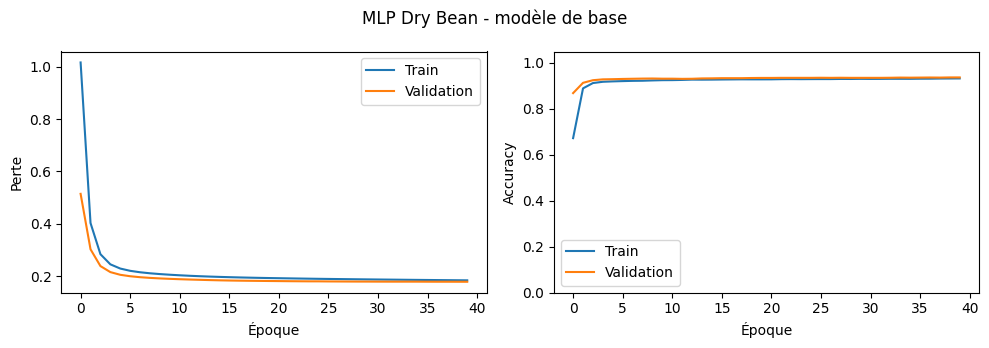

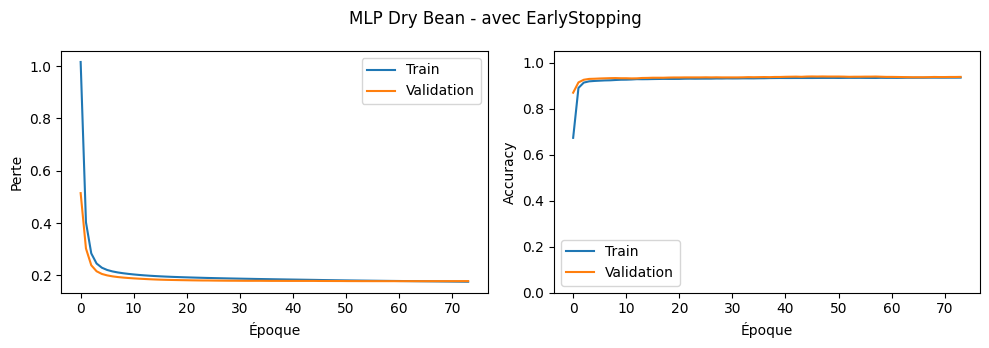

In [ ]:
plot_history(history, "MLP Dry Bean - modèle de base")
plot_history(early_history, "MLP Dry Bean - avec EarlyStopping")

## Étape 8 : Évaluation sur la validation

**Ce qu'on fait :** `evaluate`, `predict` (forme (2722, 7)), `argmax`, rapport de classification, matrice de confusion avec les noms des haricots.

**Pourquoi :**
- `argmax` : on prend la classe la plus probable (pas de seuil 0,5 en multi-classes)
- l'accuracy globale peut cacher un mauvais résultat sur une classe rare

**Définitions :**
- **précision** : parmi les images prédites dans une classe, part de celles qui sont correctes
- **rappel** : parmi les vrais éléments d'une classe, part de ceux retrouvés
- **F1 macro** : moyenne du F1 de chaque classe, toutes les classes comptent autant

**À observer :** les confusions entre haricots de formes proches.

              precision    recall  f1-score   support

    BARBUNYA      0.935     0.924     0.930       264
      BOMBAY      1.000     1.000     1.000       105
        CALI      0.933     0.933     0.933       326
    DERMASON      0.927     0.944     0.935       709
       HOROZ      0.959     0.959     0.959       386
       SEKER      0.980     0.963     0.971       405
        SIRA      0.895     0.890     0.892       527

    accuracy                          0.937      2722
   macro avg      0.947     0.945     0.946      2722
weighted avg      0.937     0.937     0.937      2722



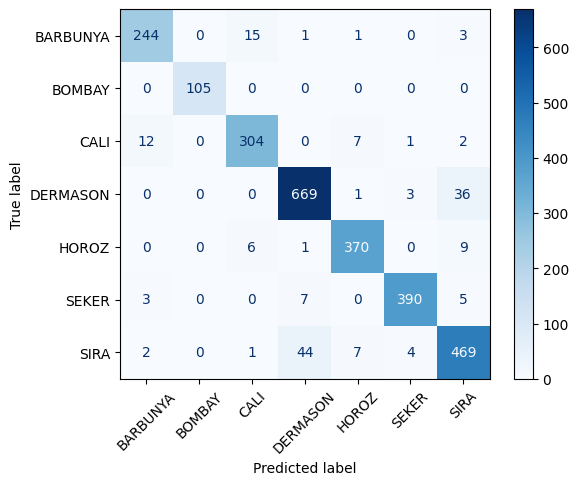

In [ ]:
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)
prob_val = model.predict(X_val_s, verbose=0)      # forme (2722, 7)
pred_val = np.argmax(prob_val, axis=1)
print(classification_report(y_val, pred_val, target_names=le.classes_, digits=3))
cm = confusion_matrix(y_val, pred_val)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap="Blues", xticks_rotation=45)

## Étape 9 : Comparer des réglages

**Règle :** un seul réglage change à la fois, avec un **modèle neuf** à chaque essai (sinon on repart de poids déjà entraînés et la comparaison est faussée).

| Comparaison | Ce qu'on cherche à comprendre |
|---|---|
| Taux d'apprentissage (0,0001 / 0,001 / 0,05) | trop petit = lent, trop grand = risque d'instabilité |
| Adam vs SGD (même taux) | pas de « meilleur » absolu, le taux doit être adapté à l'optimiseur |
| Taille des lots (1 / 32 / tout) | même nombre d'époques ≠ même nombre de mises à jour |
| Architecture (2 / 32 / 64-32 / tanh) | plus grand n'est pas toujours meilleur |

**Critères de comparaison :** CE de validation, accuracy, **F1 macro**, nombre de paramètres.

## Étape 10 : Régularisation

**But :** limiter le surapprentissage. On teste une option à la fois sur un MLP (64, 32).

| Technique | Principe |
|---|---|
| L1 / L2 | pénalise les gros poids, donc un modèle plus simple |
| Dropout (0,25) | éteint des neurones au hasard, **uniquement à l'entraînement** |
| BatchNorm | normalise les activations internes (ne remplace pas le scaler) |

**À retenir :**
- avec L1/L2, la perte de `evaluate` inclut la pénalité, d'où la comparaison avec la **CE de validation sans pénalité**
- aucune option n'est systématiquement meilleure
- ici le surapprentissage est faible, donc l'effet peut être minime

## Étape 11 : EarlyStopping

**Réglage :** `monitor="val_loss"`, `patience=8`, `restore_best_weights=True`, maximum 100 époques.

**Principe :** l'entraînement s'arrête quand la perte de validation ne s'améliore plus pendant 8 époques, puis on revient aux meilleurs poids.

**À retenir :**
- époques exécutées ≈ meilleure époque + 8
- l'arrêt avant 100 époques n'est pas garanti
- un callback EarlyStopping doit être neuf pour chaque modèle

In [ ]:
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=64, n_classes=10):
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:
        net.add(layers.Dense(units, kernel_regularizer=penalty))
        if batchnorm:
            net.add(layers.BatchNormalization())
        net.add(layers.Activation(activation))
        if dropout > 0:
            net.add(layers.Dropout(dropout))
    net.add(layers.Dense(n_classes, activation="softmax"))
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                           restore_best_weights=True)
early_model = create_model(input_dim=16, n_classes=7)
early_history = early_model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                                epochs=100, batch_size=32,
                                callbacks=[early_stop], verbose=0)

## Étape 12 : Sauvegarde et rechargement

**Ce qu'on fait :** `save("modele_drybean.keras")`, `load_model`, vérification que les prédictions sont identiques.

**Pour une application, il faut sauvegarder 3 éléments :**
1. le modèle `.keras` (architecture + poids)
2. le `StandardScaler` (le fichier `.keras` ne le contient pas), à appliquer avec `transform`, jamais un nouveau `fit`
3. le `LabelEncoder`, pour retraduire 0 à 6 en noms de haricots

In [ ]:
early_model.save("modele_drybean.keras")
loaded_model = keras.models.load_model("modele_drybean.keras")

## Étape 13 : Test final et conclusion

**Test :** le modèle est choisi **sur la validation** (F1 macro le plus élevé), puis évalué **une seule fois** sur le test et comparé à une baseline qui prédit toujours la classe majoritaire.

**Conclusion :**
- le MLP atteint ≈ 93 % d'accuracy, sans surapprentissage ni sous-apprentissage (courbes train/validation proches)
- les erreurs concernent surtout des haricots de formes proches
- limite : classes déséquilibrées, donc les classes rares sont moins fiables
- les réglages n'ont pas été modifiés après avoir regardé le test